This is the intro to my project

In [16]:
# Importing necessary tools

import glob
import os

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["image.cmap"] = "coolwarm"

print("xarray", xr.__version__)



xarray 2025.6.1


In [26]:
print("Current directory:", os.getcwd())
print("Files here:", os.listdir())
os.chdir("../project1")
print("Current directory:", os.getcwd())

Current directory: /Users/jesse/290A/Project1
Files here: ['.DS_Store', 'Project1.ipynb', 'weather_era5_xarray.ipynb', '.ipynb_checkpoints', 'data:']
Current directory: /Users/jesse/290A/Project1


In [27]:
# Opening the Dataset

DATA_DIR = "data:/data"

all_files = sorted(glob.glob(os.path.join(DATA_DIR, "*", "*.nc")))
print(f"Found {len(all_files)} files in {DATA_DIR}")
for f in all_files[:5]:
    print("  ", os.path.relpath(f, DATA_DIR))
print("   ...")

Found 60 files in data:/data
   2009_JanFeb/10m_u_component_of_wind_stream-oper_daily-mean.nc
   2009_JanFeb/10m_v_component_of_wind_0_daily-mean.nc
   2009_JanFeb/2m_temperature_0_daily-mean.nc
   2009_JanFeb/mean_sea_level_pressure_0_daily-mean.nc
   2009_JanFeb/total_precipitation_0_daily-mean.nc
   ...


In [28]:
# Creating a subset of the main data that represents temperature
temp_files = sorted(glob.glob(os.path.join(DATA_DIR, "*", "*2m_temperature*nc")))

ds_temp = xr.open_mfdataset(temp_files, combine = "by_coords")
ds_temp

<xarray.Dataset> Size: 73MB
Dimensions:     (valid_time: 730, latitude: 105, longitude: 237)
Coordinates:
    number      int64 8B 0
  * latitude    (latitude) float64 840B 50.0 49.75 49.5 ... 24.5 24.25 24.0
  * longitude   (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31
Data variables:
    t2m         (valid_time, latitude, longitude) float32 73MB dask.array<chunksize=(59, 105, 237), meta=np.ndarray>
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-12-20T19:39 GRIB to CDM+CF via cfgrib-0.9.1...

In [29]:
# Extracting the usuable DataArray from the Dataset

T2M = ds_temp["t2m"]
T2M


<xarray.DataArray 't2m' (valid_time: 730, latitude: 105, longitude: 237)> Size: 73MB
dask.array<concatenate, shape=(730, 105, 237), dtype=float32, chunksize=(62, 105, 237), chunktype=numpy.ndarray>
Coordinates:
    number      int64 8B 0
  * latitude    (latitude) float64 840B 50.0 49.75 49.5 ... 24.5 24.25 24.0
  * longitude   (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31
Attributes: (12/32)
    GRIB_paramId:                             167
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      24885
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               K
    long_name:                                2 metre temperature
    units:                                    K
    standard_name:                            unknown
    GRIB_surface:                             0.0

In [30]:
# Checking units and Fixing accordingly
print ("Units: ", T2M.attrs.get("units"))
T2M_C = T2M - 273.15
T2M_C.attrs["units"] = "degC"
print ("Units: ", T2M_C.attrs.get("units"))

Units:  K
Units:  degC


In [31]:
# Creating new subsets of temp that corresponds to 2009 and 2010 respectively
Temp = T2M_C.sel(valid_time = slice( "2009-01-01", "2010-12-31"))
display(Temp)

<xarray.DataArray 't2m' (valid_time: 730, latitude: 105, longitude: 237)> Size: 73MB
dask.array<sub, shape=(730, 105, 237), dtype=float32, chunksize=(62, 105, 237), chunktype=numpy.ndarray>
Coordinates:
    number      int64 8B 0
  * latitude    (latitude) float64 840B 50.0 49.75 49.5 ... 24.5 24.25 24.0
  * longitude   (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31
Attributes:
    units:    degC

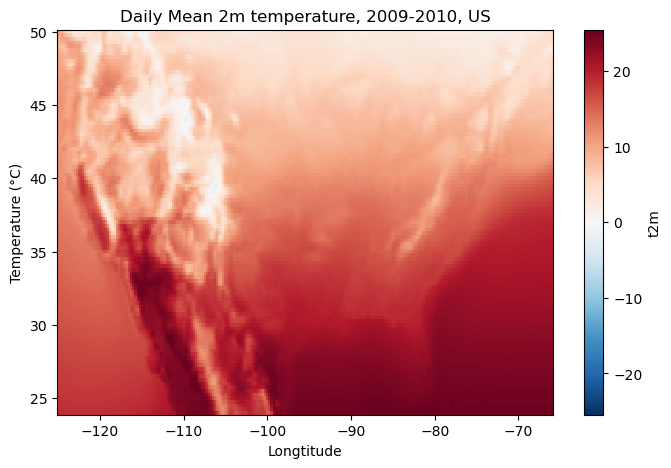

In [32]:
# Test Plot for Temperature across the US in 2009
temp_test = Temp.mean(dim="valid_time").plot()

plt.title("Daily Mean 2m temperature, 2009-2010, US")
plt.xlabel("Longtitude")
plt.ylabel("Temperature (°C)")
plt.show()
        


In [33]:
# Test Plot for Temperature Across the US 

In [34]:
# Later when we get more specific on location we can use .isel with lat and lon
print(Temp.latitude)
print(Temp.longitude)

<xarray.DataArray 'latitude' (latitude: 105)> Size: 840B
array([50.  , 49.75, 49.5 , 49.25, 49.  , 48.75, 48.5 , 48.25, 48.  , 47.75,
       47.5 , 47.25, 47.  , 46.75, 46.5 , 46.25, 46.  , 45.75, 45.5 , 45.25,
       45.  , 44.75, 44.5 , 44.25, 44.  , 43.75, 43.5 , 43.25, 43.  , 42.75,
       42.5 , 42.25, 42.  , 41.75, 41.5 , 41.25, 41.  , 40.75, 40.5 , 40.25,
       40.  , 39.75, 39.5 , 39.25, 39.  , 38.75, 38.5 , 38.25, 38.  , 37.75,
       37.5 , 37.25, 37.  , 36.75, 36.5 , 36.25, 36.  , 35.75, 35.5 , 35.25,
       35.  , 34.75, 34.5 , 34.25, 34.  , 33.75, 33.5 , 33.25, 33.  , 32.75,
       32.5 , 32.25, 32.  , 31.75, 31.5 , 31.25, 31.  , 30.75, 30.5 , 30.25,
       30.  , 29.75, 29.5 , 29.25, 29.  , 28.75, 28.5 , 28.25, 28.  , 27.75,
       27.5 , 27.25, 27.  , 26.75, 26.5 , 26.25, 26.  , 25.75, 25.5 , 25.25,
       25.  , 24.75, 24.5 , 24.25, 24.  ])
Coordinates:
    number    int64 8B 0
  * latitude  (latitude) float64 840B 50.0 49.75 49.5 49.25 ... 24.5 24.25 24.0
Attributes:


In [35]:
# Creating subset for preciptiation values 
precip_files = sorted(glob.glob(os.path.join(DATA_DIR, "*", "*total_precipitation*.nc")))

ds_precip = xr.open_mfdataset(precip_files, combine = "by_coords")
ds_precip

<xarray.Dataset> Size: 73MB
Dimensions:     (valid_time: 730, latitude: 105, longitude: 237)
Coordinates:
    number      int64 8B 0
  * latitude    (latitude) float64 840B 50.0 49.75 49.5 ... 24.5 24.25 24.0
  * longitude   (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31
Data variables:
    tp          (valid_time, latitude, longitude) float32 73MB dask.array<chunksize=(59, 105, 237), meta=np.ndarray>
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-12-20T19:43 GRIB to CDM+CF via cfgrib-0.9.1...

In [36]:
#Fixing Precip Units
P = ds_precip["tp"]
print(P.attrs.get("units"))

P_mm = P*1000
P_mm.attrs["units"] = "mm/day"
print(P_mm.attrs.get("units"))

m
mm/day


In [37]:
# Seperating Precip into 2009 and 2010 
Precip = P_mm.sel(valid_time = slice("2009-01-01", "2010-12-31"))

display(Precip)



<xarray.DataArray 'tp' (valid_time: 730, latitude: 105, longitude: 237)> Size: 73MB
dask.array<mul, shape=(730, 105, 237), dtype=float32, chunksize=(62, 105, 237), chunktype=numpy.ndarray>
Coordinates:
    number      int64 8B 0
  * latitude    (latitude) float64 840B 50.0 49.75 49.5 ... 24.5 24.25 24.0
  * longitude   (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31
Attributes:
    units:    mm/day

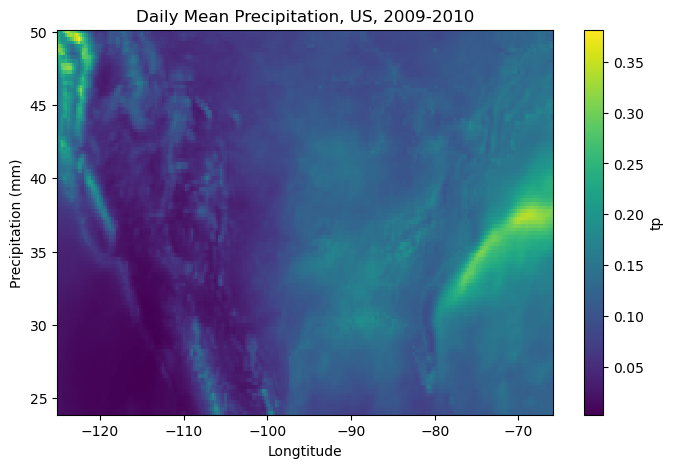

In [38]:
# Test plot for preciptiation 2009 
precip_test= Precip.mean(dim ="valid_time").plot()

plt.title("Daily Mean Precipitation, US, 2009-2010")
plt.xlabel("Longtitude")
plt.ylabel("Precipitation (mm)")
plt.show()

Nearest grid point: 36.75 -119.5


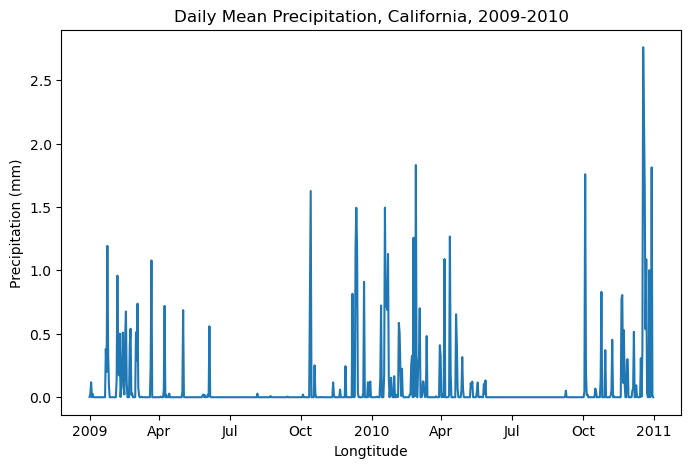

In [46]:
# Now that we have our precip and temp data for all of the US, we must shrink it down to our AOI (Cali)
lat_cali = 36.78
lon_cali = -119.42

precip_cali = Precip.sel(latitude=lat_cali, longitude=lon_cali, method ="nearest")
print("Nearest grid point:", float(precip_cali.latitude), float(precip_cali.longitude))

precip_test_cali = precip_cali.plot()

plt.title("Daily Mean Precipitation, California, 2009-2010")
plt.xlabel("Longtitude")
plt.ylabel("Precipitation (mm)")
plt.show()
                         


Nearest grid point: 36.75 -119.5


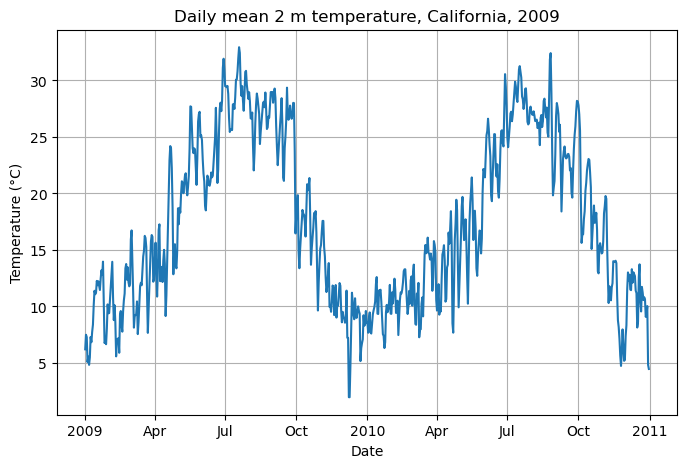

In [48]:
temp_cali = Temp.sel(latitude=lat_cali, longitude=lon_cali, method ="nearest")
print("Nearest grid point:", float(temp_cali.latitude), float(temp_cali.longitude))

temp_cali.plot()
plt.title("Daily mean 2 m temperature, California, 2009")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.grid(True)
plt.show()